[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/08_optimization.ipynb)

*Math for Data Science & ML · Notebook 8 of 10*

# Gradients & Optimisation

How machines learn: partial derivatives, the gradient, gradient descent and learning rates, fitting a line by descent, backpropagation through a neuron, logistic regression, Hessians and convexity.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Gradient descent is walking downhill in fog: you feel the slope under your feet and take a step.

**What interviewers really test here:** Learning rate effects, local minima, momentum and convexity.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Functions of several variables and partial derivatives *(Basics)*
- [ ] 2. Gradient by hand *(Basics)*
- [ ] 3. The gradient: the uphill arrow *(Core)*
- [ ] 4. Gradient descent *(Core)*
- [ ] 5. Gradient descent in 2-D, by hand *(Core)*
- [ ] 6. Exactly why learning rates fail *(Core)*
- [ ] 7. Training a model: loss, gradient, loop *(Advanced)*
- [ ] 8. Backpropagation, curvature and convexity *(Advanced)*
- [ ] 9. Training one point by hand *(Advanced)*
- [ ] 10. Local minimums, saddles and convexity *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Multivariable calculus

- **Partial derivative** ∂f/∂xᵢ: derivative with respect to xᵢ, all other variables held constant.
- **Gradient** ∇f = (∂f/∂x₁, …, ∂f/∂xₙ): direction of steepest ascent; ‖∇f‖ is the steepest slope; ∇f ⟂ level curves.
- **Directional derivative** D\_u f = ∇f·u for a unit vector u.
- **Jacobian**: for a vector-valued function, the matrix of all first partials (one row per output).
- **Hessian** H: the matrix of second partials, Hᵢⱼ = ∂²f/∂xᵢ∂xⱼ (symmetric for smooth f).
- **Multivariable chain rule**: dL/dx = Σ (∂L/∂uᵢ)(∂uᵢ/∂x) — sum over every path.



| f(x) | ∇f |
| --- | --- |
| aᵀx | a |
| xᵀAx | (A + Aᵀ)x |
| ‖x‖² | 2x |
| ‖Xw − y‖² | 2Xᵀ(Xw − y) |

### Optimality conditions

- First order: at an interior minimum ∇f = 0 (a **stationary point**).
- Second order: H positive definite (all eigenvalues &gt; 0) ⇒ local minimum; negative definite ⇒ maximum; mixed signs ⇒ **saddle point** (common in deep learning).
- **Convex** f (H ⪰ 0 everywhere): every local minimum is global. MSE linear regression and log-loss logistic regression are convex; neural networks are not.

### Gradient-based algorithms

| Method | Update | Notes |
| --- | --- | --- |
| Gradient descent | w ← w − η∇L(w) | η = learning rate; converges for η &lt; 2/λ\_max on quadratics |
| Stochastic / mini-batch GD | gradient on a random batch | cheap, noisy steps; the default for big data |
| Momentum | v ← βv + ∇L; w ← w − ηv | damps zig-zags in narrow valleys |
| Adam | momentum + per-weight step sizes | default optimiser for deep learning |
| Newton | w ← w − H⁻¹∇L | very fast near the minimum, but H is expensive |



Practical tips: scale features, watch the loss curve, lower η if the loss oscillates or explodes, use learning-rate schedules, and add L2 regularisation λ‖w‖² (gradient term 2λw) to fight overfitting.

### Backpropagation

A network computes a chain x → z₁ → a₁ → z₂ → … → L. Backprop stores the forward values, then walks backwards multiplying local derivatives (the chain rule), reusing each intermediate result, so the full gradient costs about as much as one forward pass. Frameworks (PyTorch, TensorFlow, JAX) do this automatically — **automatic differentiation**. Vanishing gradients happen when many local derivatives &lt; 1 (e.g. sigmoid's max is 0.25) are multiplied together — a reason ReLU became popular.

---
# Part 2: Lessons, step by step

## Lesson 1: Functions of several variables and partial derivatives

*Level: Basics*

A model's loss depends on **many** weights at once: L(w₁, w₂, …). Picture a landscape: two inputs (x, y) and the height f(x, y).



A **partial derivative** ∂f/∂x asks: "if I move only in the x direction, keeping y fixed, how steep is it?" Compute it like an ordinary derivative, treating every other variable as a constant:



```python
f(x, y) = x²y + 3y²
∂f/∂x = 2xy          (y is a constant)
∂f/∂y = x² + 6y      (x is a constant)
```

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

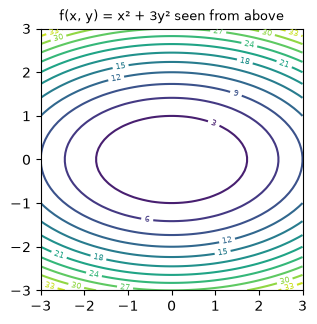

In [2]:
def landscape():
    x = np.linspace(-3, 3, 60)
    y = np.linspace(-3, 3, 60)
    X, Y = np.meshgrid(x, y)
    Z = X ** 2 + 3 * Y ** 2
    fig, ax = plt.subplots(figsize=(4.2, 3.4))
    cs = ax.contour(X, Y, Z, levels=12)
    ax.clabel(cs, fontsize=6)
    ax.set_title("f(x, y) = x² + 3y² seen from above", fontsize=9)
    ax.set_aspect("equal")


landscape()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q13](#q13). Try one now, or carry on and do them in Part 3.

## Lesson 2: Gradient by hand

*Level: Basics*

f(x, y) = x² + 3y², at the point (2, 1).



1. **Partial derivatives:** ∂f/∂x = 2x, treating y as fixed; ∂f/∂y = 6y, treating x as fixed.
2. **At (2, 1):** ∇f = (4, 6).
3. **Steepness:** ‖∇f‖ = √(16 + 36) = 7.21.
4. **Steepest way up:** (4, 6) / 7.21 = (0.555, 0.832).
5. **Steepest way down:** the opposite direction.



#### Check it with a tiny step



f(2, 1) = 7. Move 0.01 in x: f(2.01, 1) = 7.0401. The rise of 0.0401 for a step of 0.01 gives a slope of about 4 ✓.



#### Reading contours



Contour lines join points of equal height, like a hiking map. Lines close together mean steep ground, and the gradient always crosses them at right angles. Walking along a contour keeps your height constant, so all the change is across it.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def gradient_by_hand():
    def f(x, y):
        return x ** 2 + 3 * y ** 2

    gradient = np.array([2 * 2, 6 * 1])
    size = np.linalg.norm(gradient)
    uphill = gradient / size
    tiny_step = (f(2.01, 1) - f(2, 1)) / 0.01
    other_direction = (f(2, 1.01) - f(2, 1)) / 0.01


gradient_by_hand()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. f() returns 7.040099999999999
2. f() returns 7
3. f() returns 7.0603
4. f() returns 7
5. gradient\_by\_hand() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q8](#q8), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 3: The gradient: the uphill arrow

*Level: Core*

Collect all the partial derivatives into one vector: the **gradient** ∇f = (∂f/∂x, ∂f/∂y, …).




- ∇f points in the direction of **steepest ascent**; its length is how steep.
- −∇f points **steepest downhill**.
- The rate of change in any direction u is ∇f·u (the **directional derivative**).
- At the bottom of a valley ∇f = 0.



On a contour map the gradient arrows always cross the contour lines at right angles.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

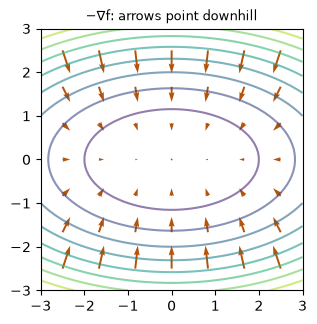

In [4]:
def gradient_arrows():
    x = np.linspace(-3, 3, 60)
    X, Y = np.meshgrid(x, x)
    Z = X ** 2 + 3 * Y ** 2
    gx, gy = np.meshgrid(np.linspace(-2.5, 2.5, 7), np.linspace(-2.5, 2.5, 7))
    fig, ax = plt.subplots(figsize=(4.2, 3.4))
    ax.contour(X, Y, Z, levels=10, alpha=0.6)
    ax.quiver(gx, gy, -2 * gx, -6 * gy, color="#b45309")
    ax.set_title("−∇f: arrows point downhill", fontsize=9)
    ax.set_aspect("equal")


gradient_arrows()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q7](#q7), [Q8](#q8), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 4: Gradient descent

*Level: Core*

To find the lowest point when you can't see the whole landscape: look at the slope under your feet and take a small step downhill. Repeat.



**w ← w − learning\_rate × ∇L(w)**



The **learning rate** controls the step size:



- too small → painfully slow
- too big → overshoots, bounces, even **diverges** (the loss grows)
- just right → smooth decrease



Long narrow valleys (features on very different scales) make descent zig-zag — another reason to scale features. Every neural network, from a single neuron to GPT, is trained by variations of this loop (SGD, momentum, Adam).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

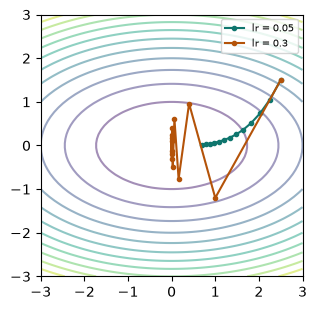

In [5]:
def descent_paths():
    def run(lr, steps=12):
        p = np.array([2.5, 1.5])
        path = [p]
        for _ in range(steps):
            p = p - lr * np.array([2 * p[0], 6 * p[1]])
            path.append(p)
        return np.array(path)
    x = np.linspace(-3, 3, 60)
    X, Y = np.meshgrid(x, x)
    fig, ax = plt.subplots(figsize=(4.4, 3.4))
    ax.contour(X, Y, X ** 2 + 3 * Y ** 2, levels=12, alpha=0.5)
    for lr, colour in [(0.05, "#0f766e"), (0.3, "#b45309")]:
        path = run(lr)
        ax.plot(path[:, 0], path[:, 1], "o-", markersize=3, color=colour, label=f"lr = {lr}")
    ax.legend(fontsize=7)
    ax.set_aspect("equal")


descent_paths()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q5](#q5), [Q9](#q9), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 5: Gradient descent in 2-D, by hand

*Level: Core*

Minimise f = x² + 3y² from (2, 1), with learning rate 0.1. The gradient is (2x, 6y).



| Step | Point | f | Gradient | Move = −0.1 × gradient |
| --- | --- | --- | --- | --- |
| 0 | (2.000, 1.000) | 7.000 | (4, 6) | (−0.4, −0.6) |
| 1 | (1.600, 0.400) | 3.040 | (3.2, 2.4) | (−0.32, −0.24) |
| 2 | (1.280, 0.160) | 1.715 | (2.56, 0.96) | (−0.256, −0.096) |
| 3 | (1.024, 0.064) | 1.061 |   |   |



Notice two things:



- **Steps shrink on their own**, as the gradient gets smaller near the bottom.
- **y falls faster than x,** because the bowl is steeper in y. Different steepness in different directions is why feature scaling speeds up training.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
def descent_table():
    point = np.array([2.0, 1.0])
    history = []
    for step in range(4):
        value = point[0] ** 2 + 3 * point[1] ** 2
        history.append((point.round(3).tolist(), round(float(value), 3)))
        gradient = np.array([2 * point[0], 6 * point[1]])
        point = point - 0.1 * gradient


descent_table()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q10](#q10), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 6: Exactly why learning rates fail

*Level: Core*

For f(x) = x², one step gives x − η·2x = **(1 − 2η)·x**. So each step multiplies x by the same factor. Starting from x = 5:



| η | Factor | x after each step | Behaviour |
| --- | --- | --- | --- |
| 0.1 | 0.8 | 4, 3.2, 2.56, 2.05 | slow and steady |
| 0.25 | 0.5 | 2.5, 1.25, 0.63, 0.31 | faster |
| 0.5 | 0 | 0, 0, 0, 0 | exact in one step |
| 1.0 | −1 | −5, 5, −5, 5 | bounces forever |
| 1.1 | −1.2 | −6, 7.2, −8.64, 10.37 | explodes |



So it converges only if |1 − 2η| &lt; 1, meaning η &lt; 1.



#### The narrow valley problem



On a bowl with different steepness, the steepest direction limits η. Too large and that direction explodes. Small enough for it, and the gentle direction crawls. The ratio of steepest to gentlest curvature is the **condition number**. Scaling features makes it smaller, and momentum and Adam help too.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

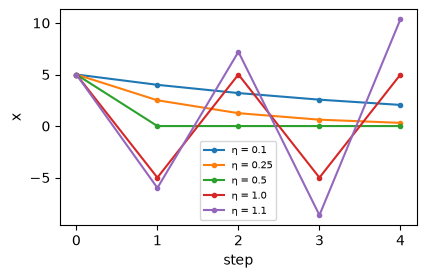

In [7]:
def rate_table():
    table = {}
    for eta in [0.1, 0.25, 0.5, 1.0, 1.1]:
        x = 5.0
        path = []
        for _ in range(4):
            x = (1 - 2 * eta) * x
            path.append(round(x, 2))
        table[eta] = path
    fig, ax = plt.subplots(figsize=(4.6, 2.8))
    for eta, path in table.items():
        ax.plot([5] + path, "o-", markersize=3, label=f"η = {eta}")
    ax.set_xlabel("step")
    ax.set_ylabel("x")
    ax.legend(fontsize=7)


rate_table()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 7: Training a model: loss, gradient, loop

*Level: Advanced*

Fit y ≈ m·x + b by gradient descent:




1. **Loss**: mean squared error L = (1/n) Σ (yᵢ − (m xᵢ + b))².
2. **Gradient** by the chain rule: ∂L/∂m = −(2/n) Σ xᵢ·errᵢ, ∂L/∂b = −(2/n) Σ errᵢ.
3. **Update** m and b, repeat until the loss stops falling.



For logistic regression the loss is log-loss, and the gradient turns out beautifully simple: Xᵀ(p − y)/n. Computing the gradient on a small random **mini-batch** instead of all the data is stochastic gradient descent (SGD).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

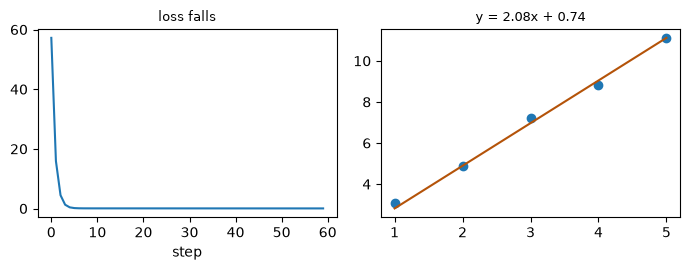

In [8]:
def training_loop():
    x = np.array([1, 2, 3, 4, 5], dtype=float)
    y = np.array([3.1, 4.9, 7.2, 8.8, 11.1])
    m = b = 0.0
    losses = []
    for step in range(60):
        err = y - (m * x + b)
        losses.append((err ** 2).mean())
        m -= 0.02 * -2 * (x * err).mean()
        b -= 0.02 * -2 * err.mean()
    fig, (left, right) = plt.subplots(1, 2, figsize=(7, 2.8))
    left.plot(losses)
    left.set_title("loss falls", fontsize=9)
    left.set_xlabel("step")
    right.scatter(x, y)
    right.plot(x, m * x + b, color="#b45309")
    right.set_title(f"y = {m:.2f}x + {b:.2f}", fontsize=9)
    fig.tight_layout()


training_loop()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q11](#q11), [Q16](#q16), [Q18](#q18), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 8: Backpropagation, curvature and convexity

*Level: Advanced*

**Backpropagation** is the chain rule run backwards. For one neuron ŷ = σ(wx + b) with loss (ŷ − y)²:



```python
dL/dŷ = 2(ŷ − y)
dŷ/dz = ŷ(1 − ŷ)          z = wx + b
dL/dw = dL/dŷ · dŷ/dz · x
dL/db = dL/dŷ · dŷ/dz · 1
```



A deep network just has more links in the chain. Always **gradient-check** new code against a numerical derivative.



The **Hessian** (matrix of second derivatives) describes curvature. If its eigenvalues are all ≥ 0 the loss is **convex** — a single bowl with no false valleys, so descent always finds the best answer. Newton's method uses the Hessian to take smarter steps.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [9]:
def backprop_demo():
    w, b, x, y = 0.5, 0.1, 2.0, 1.0
    z = w * x + b
    y_hat = 1 / (1 + math.exp(-z))
    loss = (y_hat - y) ** 2
    dL_dyhat = 2 * (y_hat - y)
    dyhat_dz = y_hat * (1 - y_hat)
    dL_dw = dL_dyhat * dyhat_dz * x
    dL_db = dL_dyhat * dyhat_dz
    w_new = w - 1.0 * dL_dw
    b_new = b - 1.0 * dL_db
    y_hat_new = 1 / (1 + math.exp(-(w_new * x + b_new)))
    loss_new = (y_hat_new - y) ** 2


backprop_demo()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q17](#q17), [Q13](#q13), [Q14](#q14), [Q19](#q19), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 9: Training one point by hand

*Level: Advanced*

Model ŷ = wx + b. With one example x = 2, y = 10, and current weights w = 3, b = 1.



#### Forward



ŷ = 3(2) + 1 = 7. Error ŷ − y = −3. Loss L = (−3)² = 9.



#### Backward, with the chain rule



- ∂L/∂w = 2(ŷ − y) × x = 2(−3)(2) = **−12**
- ∂L/∂b = 2(ŷ − y) × 1 = **−6**



Negative gradients say: raising the weights lowers the loss. Sensible, since the prediction is too low. w gets a bigger push because x = 2 multiplies its effect.



#### Update with η = 0.01



w = 3 + 0.12 = 3.12 and b = 1 + 0.06 = 1.06. Then ŷ = 7.3, and the loss falls from 9 to **7.29**.



For many examples, average these gradients over all of them (or over a mini-batch). That's all the training of linear regression is. A neural network just has a longer chain.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [10]:
def one_point_training():
    x, y, w, b = 2.0, 10.0, 3.0, 1.0
    prediction = w * x + b
    loss = (prediction - y) ** 2
    dL_dw = 2 * (prediction - y) * x
    dL_db = 2 * (prediction - y)
    w_new = w - 0.01 * dL_dw
    b_new = b - 0.01 * dL_db
    new_prediction = w_new * x + b_new
    new_loss = (new_prediction - y) ** 2


one_point_training()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q11](#q11), [Q16](#q16), [Q12](#q12), [Q17](#q17), [Q15](#q15), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 10: Local minimums, saddles and convexity

*Level: Advanced*

A flat point (∇f = 0) isn't always the bottom. The second derivatives tell them apart.



| Function | Hessian eigenvalues at (0, 0) | Type |
| --- | --- | --- |
| x² + y² | 2, 2 (all positive) | minimum |
| −x² − y² | −2, −2 (all negative) | maximum |
| x² − y² | 2, −2 (mixed) | **saddle** |



#### Starting point matters



f(x) = x⁴ − 3x² + x has two valleys. The demo starts gradient descent from two points, and each one reaches a different valley, with different final values.



#### Convex: the easy case



A bowl with one bottom: any valley is the best one. Linear and logistic regression are convex, so they always reach the best answer.



Neural networks aren't convex, yet they train well in practice. In very high dimensions most flat points are saddles rather than bad valleys, and the noise from mini-batches helps escape them.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

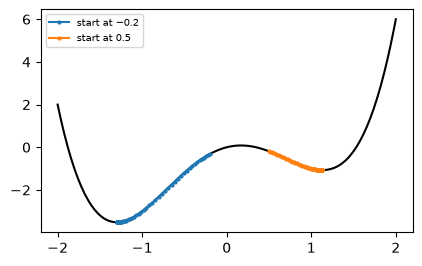

In [11]:
def two_valleys():
    def f(x):
        return x ** 4 - 3 * x ** 2 + x

    def descend(x, steps=100, lr=0.01):
        path = [x]
        for _ in range(steps):
            x = x - lr * (4 * x ** 3 - 6 * x + 1)
            path.append(x)
        return np.array(path)

    left, right = descend(-0.2), descend(0.5)
    ends = (round(float(left[-1]), 3), round(float(f(left[-1])), 3), round(float(right[-1]), 3), round(float(f(right[-1])), 3))
    xs = np.linspace(-2, 2, 200)
    fig, ax = plt.subplots(figsize=(4.8, 2.9))
    ax.plot(xs, f(xs), color="black")
    ax.plot(left, f(left), "o-", markersize=2, label="start at −0.2")
    ax.plot(right, f(right), "o-", markersize=2, label="start at 0.5")
    ax.legend(fontsize=7)


two_valleys()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q19](#q19), [Q20](#q20). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Partial Derivatives

🟢 Warm-up · *∂f/∂x and ∂f/∂y*

For f(x, y) = x²y + 3y², return (∂f/∂x, ∂f/∂y) at (x, y), rounded to 4 decimals.

**Examples**

- `x = 1, y = 2` → `(4.0, 13.0)`
- `x = 3, y = -1` → `(-6.0, 3.0)`
- `x = 0, y = 0` → `(0.0, 0.0)`

In [ ]:
def partials(x, y):
    """
    For f(x, y) = x²y + 3y², return (∂f/∂x, ∂f/∂y) at (x, y), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(partials, [
    ((1, 2), (4.0, 13.0)),
    ((3, -1), (-6.0, 3.0)),
    ((0, 0), (0.0, 0.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerically: nudge one variable at a time, keep the other fixed.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

By hand: treat the other variable as a constant → (2xy, x² + 6y).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Numerically: nudge one variable at a time, keep the other fixed.

```python
def partials(x, y):
    f = lambda x, y: x * x * y + 3 * y * y
    h = 1e-5
    dfdx = (f(x + h, y) - f(x - h, y)) / (2 * h)
    dfdy = (f(x, y + h) - f(x, y - h)) / (2 * h)
    return (round(dfdx, 4) + 0.0, round(dfdy, 4) + 0.0)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** By hand: treat the other variable as a constant → (2xy, x² + 6y).

```python
def partials(x, y):
    return (float(2 * x * y), float(x * x + 6 * y))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerically: nudge one variable at a time, keep the other fixed. That costs O(1) time and O(1) space."

"I can do better: By hand: treat the other variable as a constant → (2xy, x² + 6y). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/partial-derivatives)

<a id="q2"></a>
### Q2. The Gradient Vector

🟢 Warm-up · *∇f*

For f(x, y, z) = x² + 2y² + 3z² + xy, return ∇f at the point, rounded to 4 decimals.

**Examples**

- `p = [1, 1, 1]` → `[3.0, 5.0, 6.0]`
- `p = [2, -1, 0.5]` → `[3.0, -2.0, 3.0]`

In [ ]:
def gradient(p):
    """
    For f(x, y, z) = x² + 2y² + 3z² + xy, return ∇f at the point, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gradient, [
    (([1, 1, 1],), [3.0, 5.0, 6.0]),
    (([2, -1, 0.5],), [3.0, -2.0, 3.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Central difference in each of the three directions.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Analytic gradient (2x + y, 4y + x, 6z) with NumPy.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Central difference in each of the three directions.

```python
def gradient(p):
    f = lambda v: v[0] ** 2 + 2 * v[1] ** 2 + 3 * v[2] ** 2 + v[0] * v[1]
    h = 1e-5
    out = []
    for i in range(3):
        up, down = list(p), list(p)
        up[i] += h
        down[i] -= h
        out.append(round((f(up) - f(down)) / (2 * h), 4) + 0.0)
    return out
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Analytic gradient (2x + y, 4y + x, 6z) with NumPy.

```python
def gradient(p):
    x, y, z = p
    return np.array([2 * x + y, 4 * y + x, 6 * z], dtype=float).round(4)
```

**Cost:** O(1) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Central difference in each of the three directions. That costs O(d) time and O(d) space."

"I can do better: Analytic gradient (2x + y, 4y + x, 6z) with NumPy. That's O(1) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/the-gradient-vector)

<a id="q3"></a>
### Q3. Steepest Downhill Direction

🟢 Warm-up · *−∇f / ‖∇f‖*

For f(x, y) = x² + 3y², return the unit direction of steepest descent at p, rounded to 4 decimals.

**Examples**

- `p = [1, 1]` → `[-0.3162, -0.9487]`
- `p = [2, 0]` → `[-1.0, 0.0]`
- `p = [0, -1]` → `[0.0, 1.0]`

In [ ]:
def steepest(p):
    """
    For f(x, y) = x² + 3y², return the unit direction of steepest descent at p,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(steepest, [
    (([1, 1],), [-0.3162, -0.9487]),
    (([2, 0],), [-1.0, 0.0]),
    (([0, -1],), [0.0, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerical gradient, flip its sign, divide by its length.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Analytic gradient (2x, 6y), then `-g / np.linalg.norm(g)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Numerical gradient, flip its sign, divide by its length.

```python
def steepest(p):
    f = lambda x, y: x * x + 3 * y * y
    h = 1e-6
    gx = (f(p[0] + h, p[1]) - f(p[0] - h, p[1])) / (2 * h)
    gy = (f(p[0], p[1] + h) - f(p[0], p[1] - h)) / (2 * h)
    n = math.sqrt(gx * gx + gy * gy)
    return [round(-gx / n, 4) + 0.0, round(-gy / n, 4) + 0.0]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Analytic gradient (2x, 6y), then `-g / np.linalg.norm(g)`.

```python
def steepest(p):
    g = np.array([2 * p[0], 6 * p[1]], dtype=float)
    return (-g / np.linalg.norm(g)).round(4) + 0.0
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerical gradient, flip its sign, divide by its length. That costs O(1) time and O(1) space."

"I can do better: Analytic gradient (2x, 6y), then `-g / np.linalg.norm(g)`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/steepest-downhill-direction)

<a id="q4"></a>
### Q4. One Gradient-Descent Step

🟢 Warm-up · *w ← w − lr·∇f*

For f(x, y) = x² + 3y², return the point after one step from p with learning rate lr, rounded to 4 decimals.

**Examples**

- `p = [1, 1], lr = 0.1` → `[0.8, 0.4]`
- `p = [2, -1], lr = 0.05` → `[1.8, -0.7]`

In [ ]:
def gd_step(p, lr):
    """
    For f(x, y) = x² + 3y², return the point after one step from p with learning
    rate lr, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gd_step, [
    (([1, 1], 0.1), [0.8, 0.4]),
    (([2, -1], 0.05), [1.8, -0.7]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Gradient numerically, then move each coordinate against it.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Analytic gradient and one vector update.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Gradient numerically, then move each coordinate against it.

```python
def gd_step(p, lr):
    f = lambda x, y: x * x + 3 * y * y
    h = 1e-6
    gx = (f(p[0] + h, p[1]) - f(p[0] - h, p[1])) / (2 * h)
    gy = (f(p[0], p[1] + h) - f(p[0], p[1] - h)) / (2 * h)
    return [round(p[0] - lr * gx, 4), round(p[1] - lr * gy, 4)]
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Analytic gradient and one vector update.

```python
def gd_step(p, lr):
    p = np.array(p, dtype=float)
    grad = np.array([2 * p[0], 6 * p[1]])
    return (p - lr * grad).round(4)
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Gradient numerically, then move each coordinate against it. That costs O(d) time and O(d) space."

"I can do better: Analytic gradient and one vector update. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/one-gradient-descent-step)

<a id="q5"></a>
### Q5. Gradient Descent in 1-D

🟢 Warm-up · *Walking downhill*

Minimise f(x) = (x − 3)² starting at x0 with learning rate lr for n steps. Return the final x, rounded to 4 decimals.

**Examples**

- `x0 = 0, lr = 0.1, n = 10` → `2.6779`
- `x0 = 10, lr = 0.25, n = 3` → `3.875`
- `x0 = 5, lr = 0.5, n = 1` → `3.0`

In [ ]:
def gd_1d(x0, lr, n):
    """
    Minimise f(x) = (x − 3)² starting at x0 with learning rate lr for n steps.
    Return the final x, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gd_1d, [
    ((0, 0.1, 10), 2.6779),
    ((10, 0.25, 3), 3.875),
    ((5, 0.5, 1), 3.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: x ← x − lr·2(x − 3).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Each step multiplies the distance to 3 by (1 − 2·lr), so x = 3 + (x0 − 3)(1 − 2lr)ⁿ.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop: x ← x − lr·2(x − 3).

```python
def gd_1d(x0, lr, n):
    x = x0
    for _ in range(n):
        grad = 2 * (x - 3)
        x = x - lr * grad
    return round(x, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Each step multiplies the distance to 3 by (1 − 2·lr), so x = 3 + (x0 − 3)(1 − 2lr)ⁿ.

```python
def gd_1d(x0, lr, n):
    return round(3 + (x0 - 3) * (1 - 2 * lr) ** n, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: x ← x − lr·2(x − 3). That costs O(n) time and O(1) space."

"I can do better: Each step multiplies the distance to 3 by (1 − 2·lr), so x = 3 + (x0 − 3)(1 − 2lr)ⁿ. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/gradient-descent-in-1-d)

<a id="q6"></a>
### Q6. Mean Squared Error of a Line

🟢 Warm-up · *The loss*

Return the MSE of predictions m·x + b on the data, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3], y = [2, 4, 7], m = 2, b = 0` → `0.3333`
- `x = [1, 2, 3], y = [2, 4, 7], m = 1, b = 1` → `3.3333`

In [ ]:
def mse(x, y, m, b):
    """
    Return the MSE of predictions m·x + b on the data, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mse, [
    (([1, 2, 3], [2, 4, 7], 2, 0), 0.3333),
    (([1, 2, 3], [2, 4, 7], 1, 1), 3.3333),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: error, square, average.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: `((y - (m*x + b))**2).mean()`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop: error, square, average.

```python
def mse(x, y, m, b):
    total = 0
    for xi, yi in zip(x, y):
        total += (yi - (m * xi + b)) ** 2
    return round(total / len(x), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised: `((y - (m*x + b))**2).mean()`.

```python
def mse(x, y, m, b):
    x, y = np.array(x), np.array(y)
    return round(((y - (m * x + b)) ** 2).mean(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: error, square, average. That costs O(n) time and O(1) space."

"I can do better: Vectorised: `((y - (m*x + b))**2).mean()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/mean-squared-error-of-a-line)

<a id="q7"></a>
### Q7. Gradient of a Quadratic Form

🟡 Interview standard · *∇(vᵀAv) = (A + Aᵀ)v*

Return the gradient of f(v) = vᵀ A v at v, rounded to 4 decimals.

**Examples**

- `A = [[2, 1], [0, 3]], v = [1, 2]` → `[6.0, 13.0]`
- `A = [[1, 2], [2, 1]], v = [1, -1]` → `[-2.0, 2.0]`

In [ ]:
def quad_grad(A, v):
    """
    Return the gradient of f(v) = vᵀ A v at v, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(quad_grad, [
    (([[2, 1], [0, 3]], [1, 2]), [6.0, 13.0]),
    (([[1, 2], [2, 1]], [1, -1]), [-2.0, 2.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerical partial derivative in each coordinate.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Matrix calculus: (A + Aᵀ)v — and 2Av when A is symmetric.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Numerical partial derivative in each coordinate.

```python
def quad_grad(A, v):
    def f(x):
        return sum(x[i] * A[i][j] * x[j] for i in range(len(x)) for j in range(len(x)))
    h = 1e-5
    out = []
    for i in range(len(v)):
        up, down = list(v), list(v)
        up[i] += h
        down[i] -= h
        out.append(round((f(up) - f(down)) / (2 * h), 4) + 0.0)
    return out
```

**Cost:** O(d³) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Matrix calculus: (A + Aᵀ)v — and 2Av when A is symmetric.

```python
def quad_grad(A, v):
    A = np.array(A, dtype=float)
    return ((A + A.T) @ np.array(v, dtype=float)).round(4)
```

**Cost:** O(d²) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerical partial derivative in each coordinate. That costs O(d³) time and O(d) space."

"I can do better: Matrix calculus: (A + Aᵀ)v — and 2Av when A is symmetric. That's O(d²) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/gradient-of-a-quadratic-form)

<a id="q8"></a>
### Q8. Directional Derivative

🟡 Interview standard · *∇f · u*

For f(x, y) = x² + y², return the rate of change at point p when moving in direction d (any length), rounded to 4 decimals.

**Examples**

- `p = [1, 2], d = [3, 4]` → `4.4`
- `p = [1, 1], d = [1, 0]` → `2.0`

In [ ]:
def directional(p, d):
    """
    For f(x, y) = x² + y², return the rate of change at point p when moving in
    direction d (any length), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(directional, [
    (([1, 2], [3, 4]), 4.4),
    (([1, 1], [1, 0]), 2.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Take a tiny step along the unit direction and measure the change.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Dot the gradient (2x, 2y) with the unit direction.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Take a tiny step along the unit direction and measure the change.

```python
def directional(p, d):
    f = lambda x, y: x * x + y * y
    length = math.sqrt(d[0] ** 2 + d[1] ** 2)
    u = (d[0] / length, d[1] / length)
    h = 1e-5
    ahead = f(p[0] + h * u[0], p[1] + h * u[1])
    behind = f(p[0] - h * u[0], p[1] - h * u[1])
    return round((ahead - behind) / (2 * h), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Dot the gradient (2x, 2y) with the unit direction.

```python
def directional(p, d):
    g = 2 * np.array(p, dtype=float)
    u = np.array(d, dtype=float) / np.linalg.norm(d)
    return round(g @ u, 4)
```

**Cost:** O(d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Take a tiny step along the unit direction and measure the change. That costs O(1) time and O(1) space."

"I can do better: Dot the gradient (2x, 2y) with the unit direction. That's O(d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/directional-derivative)

<a id="q9"></a>
### Q9. Is the Learning Rate Too Big?

🟡 Interview standard · *Loss curve*

Minimise f(x) = x² from x0 with learning rate lr. Return the loss after each of n steps, rounded to 4 decimals. (Rising losses = diverging.)

**Examples**

- `x0 = 1, lr = 0.1, n = 4` → `[0.64, 0.4096, 0.2621, 0.1678]`
- `x0 = 1, lr = 1.1, n = 4` → `[1.44, 2.0736, 2.986, 4.2998]`

In [ ]:
def loss_curve(x0, lr, n):
    """
    Minimise f(x) = x² from x0 with learning rate lr. Return the loss after each
    of n steps, rounded to 4 decimals. (Rising losses = diverging.)
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(loss_curve, [
    ((1, 0.1, 4), [0.64, 0.4096, 0.2621, 0.1678]),
    ((1, 1.1, 4), [1.44, 2.0736, 2.986, 4.2998]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simulate the steps and record x² each time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Closed form for every step at once: xₖ = x0(1 − 2lr)ᵏ.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Simulate the steps and record x² each time.

```python
def loss_curve(x0, lr, n):
    x = x0
    losses = []
    for _ in range(n):
        x = x - lr * 2 * x
        losses.append(round(x * x, 4))
    return losses
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Closed form for every step at once: xₖ = x0(1 − 2lr)ᵏ.

```python
def loss_curve(x0, lr, n):
    xs = x0 * (1 - 2 * lr) ** np.arange(1, n + 1)
    return (xs ** 2).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simulate the steps and record x² each time. That costs O(n) time and O(n) space."

"I can do better: Closed form for every step at once: xₖ = x0(1 − 2lr)ᵏ. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/is-the-learning-rate-too-big)

<a id="q10"></a>
### Q10. Descent in a Long Narrow Valley

🟡 Interview standard · *Different curvature per direction*

Minimise f(x, y) = x² + 10y² from p with learning rate lr for n steps. Return the final point, rounded to 4 decimals.

**Examples**

- `p = [1, 1], lr = 0.05, n = 10` → `[0.3487, 0.0]`
- `p = [2, 1], lr = 0.09, n = 5` → `[0.7415, -0.3277]`

In [ ]:
def narrow_valley(p, lr, n):
    """
    Minimise f(x, y) = x² + 10y² from p with learning rate lr for n steps.
    Return the final point, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(narrow_valley, [
    (([1, 1], 0.05, 10), [0.3487, 0.0]),
    (([2, 1], 0.09, 5), [0.7415, -0.3277]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop the 2-D update.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Each coordinate shrinks independently: x·(1 − 2lr)ⁿ and y·(1 − 20lr)ⁿ.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop the 2-D update.

```python
def narrow_valley(p, lr, n):
    x, y = p
    for _ in range(n):
        x, y = x - lr * 2 * x, y - lr * 20 * y
    return [round(x, 4) + 0.0, round(y, 4) + 0.0]
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Each coordinate shrinks independently: x·(1 − 2lr)ⁿ and y·(1 − 20lr)ⁿ.

```python
def narrow_valley(p, lr, n):
    shrink = np.array([1 - 2 * lr, 1 - 20 * lr]) ** n
    return (np.array(p) * shrink).round(4) + 0.0
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop the 2-D update. That costs O(n) time and O(1) space."

"I can do better: Each coordinate shrinks independently: x·(1 − 2lr)ⁿ and y·(1 − 20lr)ⁿ. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/descent-in-a-long-narrow-valley)

<a id="q11"></a>
### Q11. Gradient of the MSE

🟡 Interview standard · *∂L/∂m and ∂L/∂b*

Return (∂MSE/∂m, ∂MSE/∂b) for the line m·x + b, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3], y = [2, 4, 7], m = 2, b = 0` → `(-2.0, -0.6667)`
- `x = [1, 2, 3], y = [2, 4, 7], m = 1, b = 1` → `(-7.3333, -2.6667)`

In [ ]:
def mse_grad(x, y, m, b):
    """
    Return (∂MSE/∂m, ∂MSE/∂b) for the line m·x + b, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mse_grad, [
    (([1, 2, 3], [2, 4, 7], 2, 0), (-2.0, -0.6667)),
    (([1, 2, 3], [2, 4, 7], 1, 1), (-7.3333, -2.6667)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Chain rule term by term in a loop: each point contributes −2x·error and −2·error.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised means of −2·x·err and −2·err.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Chain rule term by term in a loop: each point contributes −2x·error and −2·error.

```python
def mse_grad(x, y, m, b):
    n = len(x)
    dm = db = 0
    for xi, yi in zip(x, y):
        err = yi - (m * xi + b)
        dm += -2 * xi * err / n
        db += -2 * err / n
    return (round(dm, 4), round(db, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised means of −2·x·err and −2·err.

```python
def mse_grad(x, y, m, b):
    x, y = np.array(x, dtype=float), np.array(y, dtype=float)
    err = y - (m * x + b)
    return (round(-2 * (x * err).mean(), 4), round(-2 * err.mean(), 4))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Chain rule term by term in a loop: each point contributes −2x·error and −2·error. That costs O(n) time and O(1) space."

"I can do better: Vectorised means of −2·x·err and −2·err. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/gradient-of-the-mse)

<a id="q12"></a>
### Q12. Chain Rule Through a Computation

🟡 Interview standard · *dy/dx of sin(3x² + 1)*

Return dy/dx of y = sin(3x² + 1) at x, rounded to 4 decimals.

**Examples**

- `x = 0.5` → `-0.5347`
- `x = 1.0` → `-3.9219`
- `x = 0` → `0.0`

In [ ]:
def chain(x):
    """
    Return dy/dx of y = sin(3x² + 1) at x, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(chain, [
    ((0.5,), -0.5347),
    ((1.0,), -3.9219),
    ((0,), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerical central difference of the whole expression.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Chain rule stage by stage: u = 3x² + 1 → du/dx = 6x; y = sin u → dy/du = cos u; multiply.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Numerical central difference of the whole expression.

```python
def chain(x):
    f = lambda t: math.sin(3 * t * t + 1)
    h = 1e-6
    return round((f(x + h) - f(x - h)) / (2 * h), 4) + 0.0
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Chain rule stage by stage: u = 3x² + 1 → du/dx = 6x; y = sin u → dy/du = cos u; multiply.

```python
def chain(x):
    u = 3 * x * x + 1
    du_dx = 6 * x
    dy_du = math.cos(u)
    return round(dy_du * du_dx, 4) + 0.0
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerical central difference of the whole expression. That costs O(1) time and O(1) space."

"I can do better: Chain rule stage by stage: u = 3x² + 1 → du/dx = 6x; y = sin u → dy/du = cos u; multiply. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/chain-rule-through-a-computation)

<a id="q13"></a>
### Q13. The Hessian Matrix

🟡 Interview standard · *Second partial derivatives*

For f(x, y) = a·x² + b·xy + c·y², return the Hessian [[f\_xx, f\_xy], [f\_yx, f\_yy]] (rounded to 2 decimals).

**Examples**

- `a = 1, b = 2, c = 3` → `[[2.0, 2.0], [2.0, 6.0]]`
- `a = 2, b = -1, c = 0.5` → `[[4.0, -1.0], [-1.0, 1.0]]`

In [ ]:
def hessian(a, b, c):
    """
    For f(x, y) = a·x² + b·xy + c·y², return the Hessian [[f_xx, f_xy], [f_yx,
    f_yy]] (rounded to 2 decimals).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hessian, [
    ((1, 2, 3), [[2.0, 2.0], [2.0, 6.0]]),
    ((2, -1, 0.5), [[4.0, -1.0], [-1.0, 1.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerical second differences at the origin.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Differentiate twice by hand: [[2a, b], [b, 2c]].

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Numerical second differences at the origin.

```python
def hessian(a, b, c):
    f = lambda x, y: a * x * x + b * x * y + c * y * y
    h = 1e-3
    fxx = (f(h, 0) - 2 * f(0, 0) + f(-h, 0)) / (h * h)
    fyy = (f(0, h) - 2 * f(0, 0) + f(0, -h)) / (h * h)
    fxy = (f(h, h) - f(h, -h) - f(-h, h) + f(-h, -h)) / (4 * h * h)
    return [[round(fxx, 2), round(fxy, 2)], [round(fxy, 2), round(fyy, 2)]]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Differentiate twice by hand: [[2a, b], [b, 2c]].

```python
def hessian(a, b, c):
    return np.array([[2 * a, b], [b, 2 * c]], dtype=float)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerical second differences at the origin. That costs O(1) time and O(1) space."

"I can do better: Differentiate twice by hand: [[2a, b], [b, 2c]]. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/the-hessian-matrix)

<a id="q14"></a>
### Q14. Is the Bowl Convex?

🟡 Interview standard · *Positive semi-definite Hessian*

f(x, y) = a·x² + b·xy + c·y². Return True if f is convex (its Hessian has no negative eigenvalues).

**Examples**

- `a = 1, b = 2, c = 3` → `True`
- `a = 2, b = -1, c = 0.5` → `True`
- `a = 1, b = 3, c = 1` → `False`

In [ ]:
def is_convex(a, b, c):
    """
    f(x, y) = a·x² + b·xy + c·y². Return True if f is convex (its Hessian has no
    negative eigenvalues).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(is_convex, [
    ((1, 2, 3), True),
    ((2, -1, 0.5), True),
    ((1, 3, 1), False),
    ((-1, 0, 1), False),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

2×2 test by hand: diagonal entries ≥ 0 and determinant ≥ 0.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.eigvalsh(H).min() >= 0` — works for any size.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** 2×2 test by hand: diagonal entries ≥ 0 and determinant ≥ 0.

```python
def is_convex(a, b, c):
    fxx, fyy, fxy = 2 * a, 2 * c, b
    det = fxx * fyy - fxy * fxy
    return fxx >= 0 and fyy >= 0 and det >= 0
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.eigvalsh(H).min() >= 0` — works for any size.

```python
def is_convex(a, b, c):
    H = np.array([[2 * a, b], [b, 2 * c]], dtype=float)
    return bool(np.linalg.eigvalsh(H).min() >= -1e-12)
```

**Cost:** O(d³) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: 2×2 test by hand: diagonal entries ≥ 0 and determinant ≥ 0. That costs O(1) time and O(1) space."

"I can do better: `np.linalg.eigvalsh(H).min() >= 0` — works for any size. That's O(d³) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/is-the-bowl-convex)

<a id="q15"></a>
### Q15. Mini-batch Gradient

🟡 Interview standard · *Averaging over a batch*

Model ŷ = w·x, loss = mean (y − ŷ)². Return the gradient dL/dw over the batch, rounded to 4 decimals.

**Examples**

- `w = 1.0, x = [1, 2, 3], y = [2, 4, 6]` → `-9.3333`
- `w = 0.0, x = [1, 2], y = [1, 1]` → `-3.0`

In [ ]:
def batch_grad(w, x, y):
    """
    Model ŷ = w·x, loss = mean (y − ŷ)². Return the gradient dL/dw over the
    batch, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(batch_grad, [
    ((1.0, [1, 2, 3], [2, 4, 6]), -9.3333),
    ((0.0, [1, 2], [1, 1]), -3.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over the batch adding each example's −2x(y − wx), then divide by the batch size.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised mean.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop over the batch adding each example's −2x(y − wx), then divide by the batch size.

```python
def batch_grad(w, x, y):
    total = 0
    for xi, yi in zip(x, y):
        total += -2 * xi * (yi - w * xi)
    return round(total / len(x), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised mean.

```python
def batch_grad(w, x, y):
    x, y = np.array(x, dtype=float), np.array(y, dtype=float)
    return round((-2 * x * (y - w * x)).mean(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over the batch adding each example's −2x(y − wx), then divide by the batch size. That costs O(n) time and O(1) space."

"I can do better: Vectorised mean. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/mini-batch-gradient)

<a id="q16"></a>
### Q16. Fit a Line by Gradient Descent

🔴 Stretch · *Training loop*

Start at m = b = 0 and run n steps of gradient descent on the MSE with learning rate lr. Return (m, b) rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4], y = [3, 5, 7, 9], lr = 0.05, steps = 2000` → `(2.0, 1.0)`
- `x = [1, 2, 3], y = [2, 4, 7], lr = 0.05, steps = 1000` → `(2.5, -0.6667)`

In [ ]:
def fit_line(x, y, lr, steps):
    """
    Start at m = b = 0 and run n steps of gradient descent on the MSE with
    learning rate lr. Return (m, b) rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fit_line, [
    (([1, 2, 3, 4], [3, 5, 7, 9], 0.05, 2000), (2.0, 1.0)),
    (([1, 2, 3], [2, 4, 7], 0.05, 1000), (2.5, -0.6667)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Plain loops: compute both gradients point by point, update, repeat.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same algorithm with vectorised gradients — the shape of every real training loop.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Plain loops: compute both gradients point by point, update, repeat.

```python
def fit_line(x, y, lr, steps):
    m = b = 0.0
    n = len(x)
    for _ in range(steps):
        dm = db = 0.0
        for xi, yi in zip(x, y):
            err = yi - (m * xi + b)
            dm += -2 * xi * err / n
            db += -2 * err / n
        m -= lr * dm
        b -= lr * db
    return (round(m, 4), round(b, 4))
```

**Cost:** O(n·steps) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Same algorithm with vectorised gradients — the shape of every real training loop.

```python
def fit_line(x, y, lr, steps):
    x, y = np.array(x, dtype=float), np.array(y, dtype=float)
    m = b = 0.0
    for _ in range(steps):
        err = y - (m * x + b)
        m -= lr * -2 * (x * err).mean()
        b -= lr * -2 * err.mean()
    return (round(m, 4), round(b, 4))
```

**Cost:** O(n·steps) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Plain loops: compute both gradients point by point, update, repeat. That costs O(n·steps) time and O(1) space."

"I can do better: Same algorithm with vectorised gradients — the shape of every real training loop. That's O(n·steps) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/fit-a-line-by-gradient-descent)

<a id="q17"></a>
### Q17. Backpropagation Through One Neuron

🔴 Stretch · *ŷ = σ(wx + b), L = (ŷ − y)²*

Return (∂L/∂w, ∂L/∂b) for one training example, rounded to 4 decimals.

**Examples**

- `w = 0.5, b = 0.1, x = 2, y = 1` → `(-0.1872, -0.0936)`
- `w = -1, b = 0, x = 1, y = 0` → `(0.1058, 0.1058)`

In [ ]:
def backprop(w, b, x, y):
    """
    Return (∂L/∂w, ∂L/∂b) for one training example, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(backprop, [
    ((0.5, 0.1, 2, 1), (-0.1872, -0.0936)),
    ((-1, 0, 1, 0), (0.1058, 0.1058)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Numerical: nudge w (then b) and see how the loss changes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Backprop: dL/dŷ = 2(ŷ − y), dŷ/dz = ŷ(1 − ŷ), dz/dw = x, dz/db = 1 — multiply along the chain.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Numerical: nudge w (then b) and see how the loss changes.

```python
def backprop(w, b, x, y):
    def loss(w, b):
        y_hat = 1 / (1 + math.exp(-(w * x + b)))
        return (y_hat - y) ** 2
    h = 1e-6
    dw = (loss(w + h, b) - loss(w - h, b)) / (2 * h)
    db = (loss(w, b + h) - loss(w, b - h)) / (2 * h)
    return (round(dw, 4), round(db, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Backprop: dL/dŷ = 2(ŷ − y), dŷ/dz = ŷ(1 − ŷ), dz/dw = x, dz/db = 1 — multiply along the chain.

```python
def backprop(w, b, x, y):
    z = w * x + b
    y_hat = 1 / (1 + math.exp(-z))
    dL_dyhat = 2 * (y_hat - y)
    dyhat_dz = y_hat * (1 - y_hat)
    dL_dz = dL_dyhat * dyhat_dz
    return (round(dL_dz * x, 4), round(dL_dz, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Numerical: nudge w (then b) and see how the loss changes. That costs O(1) time and O(1) space."

"I can do better: Backprop: dL/dŷ = 2(ŷ − y), dŷ/dz = ŷ(1 − ŷ), dz/dw = x, dz/db = 1 — multiply along the chain. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/backpropagation-through-one-neuron)

<a id="q18"></a>
### Q18. One Step of Logistic Regression

🔴 Stretch · *Log-loss gradient*

Probabilities p = σ(X·w + b). Return (new w, new b) after one gradient step on the average log-loss with learning rate lr (rounded to 4 decimals).

**Examples**

- `X = [[1, 2], [2, 1], [3, 3], [0, 1]], y = [1, 0, 1, 0], w = [0, 0], b = 0, lr = 0.5` → `([0.125, 0.1875], 0.0)`
- `X = [[1, 2], [2, 1], [3, 3], [0, 1]], y = [1, 0, 1, 0], w = [0.5, -0.5], b = 0.1, lr = 0.1` → `([0.5183, -0.4606], 0.1007)`

In [ ]:
def logreg_step(X, y, w, b, lr):
    """
    Probabilities p = σ(X·w + b). Return (new w, new b) after one gradient step
    on the average log-loss with learning rate lr (rounded to 4 decimals).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(logreg_step, [
    (([[1, 2], [2, 1], [3, 3], [0, 1]], [1, 0, 1, 0], [0, 0], 0, 0.5), ([0.125, 0.1875], 0.0)),
    (([[1, 2], [2, 1], [3, 3], [0, 1]], [1, 0, 1, 0], [0.5, -0.5], 0.1, 0.1), ([0.5183, -0.4606], 0.1007)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over examples: p − y is each one's error; accumulate error × feature.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: ∇w = Xᵀ(p − y)/n, ∇b = mean(p − y).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop over examples: p − y is each one's error; accumulate error × feature.

```python
def logreg_step(X, y, w, b, lr):
    n, d = len(X), len(w)
    gw = [0.0] * d
    gb = 0.0
    for row, target in zip(X, y):
        z = b + sum(wi * xi for wi, xi in zip(w, row))
        p = 1 / (1 + math.exp(-z))
        for j in range(d):
            gw[j] += (p - target) * row[j] / n
        gb += (p - target) / n
    new_w = [round(wi - lr * g, 4) for wi, g in zip(w, gw)]
    return (new_w, round(b - lr * gb, 4))
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised: ∇w = Xᵀ(p − y)/n, ∇b = mean(p − y).

```python
def logreg_step(X, y, w, b, lr):
    X, y, w = np.array(X, dtype=float), np.array(y, dtype=float), np.array(w, dtype=float)
    p = 1 / (1 + np.exp(-(X @ w + b)))
    grad_w = X.T @ (p - y) / len(y)
    grad_b = (p - y).mean()
    return ((w - lr * grad_w).round(4), round(b - lr * grad_b, 4))
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over examples: p − y is each one's error; accumulate error × feature. That costs O(n·d) time and O(d) space."

"I can do better: Vectorised: ∇w = Xᵀ(p − y)/n, ∇b = mean(p − y). That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/one-step-of-logistic-regression)

<a id="q19"></a>
### Q19. Bottom of a Quadratic Bowl

🔴 Stretch · *∇f = 0 ⇒ Av = b*

f(v) = ½ vᵀAv − bᵀv with A symmetric positive-definite. Return the minimiser, rounded to 4 decimals.

**Examples**

- `A = [[3, 1], [1, 2]], b = [1, 1]` → `[0.2, 0.4]`
- `A = [[2, 0], [0, 4]], b = [4, 2]` → `[2.0, 0.5]`

In [ ]:
def quad_min(A, b):
    """
    f(v) = ½ vᵀAv − bᵀv with A symmetric positive-definite. Return the
    minimiser, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(quad_min, [
    (([[3, 1], [1, 2]], [1, 1]), [0.2, 0.4]),
    (([[2, 0], [0, 4]], [4, 2]), [2.0, 0.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Gradient descent: v ← v − lr·(Av − b), many small steps.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set the gradient to zero and solve the linear system `np.linalg.solve(A, b)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Gradient descent: v ← v − lr·(Av − b), many small steps.

```python
def quad_min(A, b):
    v = [0.0] * len(b)
    for _ in range(2000):
        grad = [sum(A[i][j] * v[j] for j in range(len(v))) - b[i] for i in range(len(v))]
        v = [vi - 0.1 * g for vi, g in zip(v, grad)]
    return [round(x, 4) for x in v]
```

**Cost:** O(steps·d²) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Set the gradient to zero and solve the linear system `np.linalg.solve(A, b)`.

```python
def quad_min(A, b):
    return np.linalg.solve(np.array(A, dtype=float), np.array(b, dtype=float)).round(4)
```

**Cost:** O(d³) time, O(d²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Gradient descent: v ← v − lr·(Av − b), many small steps. That costs O(steps·d²) time and O(d) space."

"I can do better: Set the gradient to zero and solve the linear system `np.linalg.solve(A, b)`. That's O(d³) time and O(d²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/bottom-of-a-quadratic-bowl)

<a id="q20"></a>
### Q20. Newton's Method for a Minimum

🔴 Stretch · *x ← x − f′/f″*

Minimise f(x) = x⁴ − 3x² + x starting at x0 for n Newton steps. Return x rounded to 4 decimals.

**Examples**

- `x0 = 1.0, n = 5` → `1.1309`
- `x0 = -2.0, n = 6` → `-1.3008`

In [ ]:
def newton_min(x0, n):
    """
    Minimise f(x) = x⁴ − 3x² + x starting at x0 for n Newton steps. Return x
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(newton_min, [
    ((1.0, 5), 1.1309),
    ((-2.0, 6), -1.3008),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Estimate f′ and f″ numerically from f at each step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Use the exact derivatives f′ = 4x³ − 6x + 1, f″ = 12x² − 6.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Estimate f′ and f″ numerically from f at each step.

```python
def newton_min(x0, n):
    f = lambda x: x ** 4 - 3 * x ** 2 + x
    h = 1e-4
    x = x0
    for _ in range(n):
        d1 = (f(x + h) - f(x - h)) / (2 * h)
        d2 = (f(x + h) - 2 * f(x) + f(x - h)) / (h * h)
        x = x - d1 / d2
    return round(x, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Use the exact derivatives f′ = 4x³ − 6x + 1, f″ = 12x² − 6.

```python
def newton_min(x0, n):
    x = x0
    for _ in range(n):
        x = x - (4 * x ** 3 - 6 * x + 1) / (12 * x ** 2 - 6)
    return round(x, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Estimate f′ and f″ numerically from f at each step. That costs O(n) time and O(1) space."

"I can do better: Use the exact derivatives f′ = 4x³ − 6x + 1, f″ = 12x² − 6. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/optimization/newtons-method-for-a-minimum)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is a gradient in plain words?</b></summary>

An arrow pointing uphill on the loss landscape, with one component per weight saying how much the loss changes if you nudge that weight.

</details>

<details>
<summary><b>2. Why do we move against the gradient?</b></summary>

The gradient points to steepest increase; we want the loss to decrease, so we step in the opposite direction.

</details>

<details>
<summary><b>3. What happens if the learning rate is too high?</b></summary>

Steps overshoot the minimum. The loss oscillates or grows (diverges), sometimes until it becomes NaN.

</details>

<details>
<summary><b>4. Batch vs stochastic vs mini-batch gradient descent?</b></summary>

Batch uses all data per step (accurate, slow); stochastic uses one example (fast, very noisy); mini-batch uses a small group (the practical middle ground, and GPU-friendly).

</details>

<details>
<summary><b>5. What is a saddle point?</b></summary>

A stationary point that is a minimum in some directions and a maximum in others, like a horse saddle. The gradient is zero but it is not a minimum.

</details>

<details>
<summary><b>6. What is a gradient check?</b></summary>

Comparing an analytic gradient against a numerical one, (L(w + h) − L(w − h))/2h, for a few weights; a mismatch reveals a bug in backprop code.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Functions of several variables and partial derivatives
- [ ] I can explain: Gradient by hand
- [ ] I can explain: The gradient: the uphill arrow
- [ ] I can explain: Gradient descent
- [ ] I can explain: Gradient descent in 2-D, by hand
- [ ] I can explain: Exactly why learning rates fail
- [ ] I can explain: Training a model: loss, gradient, loop
- [ ] I can explain: Backpropagation, curvature and convexity
- [ ] I can explain: Training one point by hand
- [ ] I can explain: Local minimums, saddles and convexity

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Fit a Line by Gradient Descent
- [ ] [Q17](#q17) Backpropagation Through One Neuron
- [ ] [Q18](#q18) One Step of Logistic Regression
- [ ] [Q19](#q19) Bottom of a Quadratic Bowl
- [ ] [Q20](#q20) Newton's Method for a Minimum

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.